# 02 — Rolling features (FD001)

Turn raw sensor readings into features that describe the recent trend: for each sensor, the mean, standard deviation and slope over the last 10 cycles of the same engine.

In [1]:
import sys
sys.path.append("../src")
from load_data import load_test, load_train
from features import FEATURES, WINDOW, add_rolling_features

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

## 1. Build

Add the 42 rolling columns (14 sensors × mean, std, slope) to the train table. `FEATURES` is the 57-column list every model uses: `cycle`, the 14 raw sensors and the 42 rolling features.

In [3]:
train = add_rolling_features(load_train())
print("train shape:", train.shape)
print("WINDOW:", WINDOW)
print("len(FEATURES):", len(FEATURES))
print("first 6:", FEATURES[:6])
print("last 3:", FEATURES[-3:])
print("NaN in train[FEATURES]:", train[FEATURES].isna().sum().sum())

train shape: (20631, 69)
WINDOW: 10
len(FEATURES): 57
first 6: ['cycle', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8']
last 3: ['sensor_21_mean', 'sensor_21_std', 'sensor_21_slope']
NaN in train[FEATURES]: 0


## 2. Look at the numbers

Engine 1, first 12 cycles. Until cycle 10 the window holds every cycle seen so far; from cycle 11 it slides and drops the oldest cycle.

In [4]:
cols = ["cycle", "sensor_2", "sensor_2_mean", "sensor_2_std", "sensor_2_slope"]
train.query("engine_id == 1 and cycle <= 12")[cols].round(4)

,cycle,sensor_2,sensor_2_mean,sensor_2_std,sensor_2_slope
0,1,641.82,641.8200,0.0000,0.0000
1,2,642.15,641.9850,0.2333,0.3300
2,3,642.35,642.1067,0.2676,0.2650
3,4,642.35,642.1675,0.2501,0.1790
4,5,642.37,642.2080,0.2348,0.1300
5,6,642.10,642.1900,0.2146,0.0589
6,7,642.48,642.2314,0.2245,0.0679
7,8,642.56,642.2725,0.2381,0.0726
8,9,642.12,642.2556,0.2284,0.0407
9,10,641.71,642.2010,0.2759,-0.0002


## 3. Plot

Engine 1 over its whole life. The rolling mean smooths the noisy `sensor_11` reading, and the slope shows how fast it drifts upward as the engine wears.

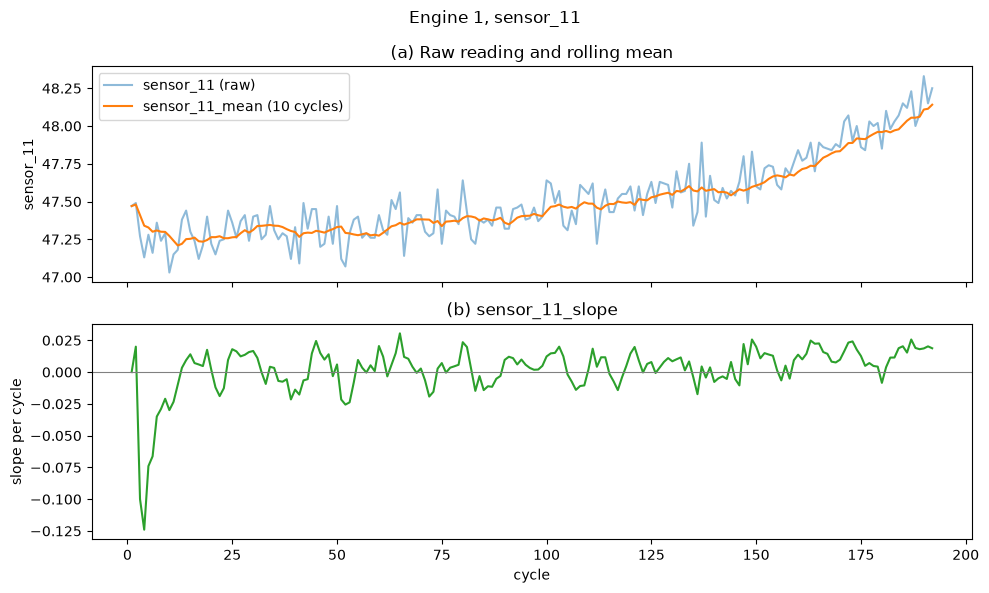

In [5]:
e1 = train.query("engine_id == 1")
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(e1["cycle"], e1["sensor_11"], alpha=0.5, label="sensor_11 (raw)")
axes[0].plot(e1["cycle"], e1["sensor_11_mean"], label="sensor_11_mean (10 cycles)")
axes[0].set_ylabel("sensor_11")
axes[0].set_title("(a) Raw reading and rolling mean")
axes[0].legend()
axes[1].plot(e1["cycle"], e1["sensor_11_slope"], color="C2")
axes[1].axhline(0, color="grey", linewidth=0.8)
axes[1].set_ylabel("slope per cycle")
axes[1].set_xlabel("cycle")
axes[1].set_title("(b) sensor_11_slope")
fig.suptitle("Engine 1, sensor_11")
fig.tight_layout()
plt.show()

## 4. The window stays inside one engine

Engine 2, cycle 1 directly follows engine 1's last cycle in the table. Its mean equals its raw value and its std and slope are 0, so nothing leaked from engine 1's near-failure cycles.

In [6]:
train.query("engine_id == 2 and cycle == 1")[cols]

,cycle,sensor_2,sensor_2_mean,sensor_2_std,sensor_2_slope
192,1,641.89,641.89,0.0,0.0


## 5. Features use only the past

Compute the features on engine 1 cut at cycle 100 and compare its last row with engine 1, cycle 100 from the full table. If they match, no feature looks at later cycles.

In [7]:
cut = add_rolling_features(load_train().query("engine_id == 1 and cycle <= 100"))
cut_row = cut[FEATURES].iloc[-1]
full_row = train.query("engine_id == 1 and cycle == 100")[FEATURES].iloc[0]
print("Identical:", cut_row.equals(full_row))

Identical: True


This matters because test engines are cut off before failure: a feature computed on a cut engine must be exactly the same as at that cycle on a full engine, otherwise the model would rely on information that does not exist at prediction time.

## 6. Which features relate to RUL

The 10 features with the largest absolute correlation with `rul`. The rolling means correlate slightly more than single readings because they are less noisy.

In [8]:
train[FEATURES].corrwith(train["rul"]).abs().sort_values(ascending=False).head(10).round(3)

cycle             0.736
sensor_4_mean     0.733
sensor_21_mean    0.730
sensor_11_mean    0.729
sensor_17_mean    0.728
sensor_15_mean    0.727
sensor_3_mean     0.726
sensor_20_mean    0.723
sensor_2_mean     0.722
sensor_7_mean     0.711
dtype: float64

## 7. Test file works too

The same function runs on the test engines. Test has no `rul` column, so it has 68 columns instead of 69.

In [9]:
add_rolling_features(load_test()).shape

(13096, 68)